In [1]:
#@title LICENSE
# Licensed under the Apache License, Version 2.0

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dimarkov/jaxpruner/blob/main/colabs/mnist_pruning.ipynb)

## Imports / Helpers

In [2]:
from absl import logging
import flax
import jax.numpy as jnp
from matplotlib import pyplot as plt
import numpy as np
import tensorflow_datasets as tfds
from flax import linen as nn
from flax.training import train_state
import jax
import optax
import tensorflow as tf
# Hide any GPUs form TensorFlow. Otherwise TF might reserve memory and make
# it unavailable to JAX.
tf.config.experimental.set_visible_devices([], "GPU")


logging.set_verbosity(logging.INFO)

I0000 00:00:1791821557.100065   77727 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791821557.886348   77727 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


W0000 00:00:1791821558.343399   77727 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
import sys
if 'google.colab' in sys.modules:
  !pip3 install git+https://github.com/dimarkov/jaxpruner
import jaxpruner
import ml_collections

## Dataset

In [4]:
def get_datasets():
  """Load MNIST train and test datasets into memory."""
  ds_builder = tfds.builder('mnist')
  ds_builder.download_and_prepare()
  train_ds = tfds.as_numpy(ds_builder.as_dataset(split='train', batch_size=-1))
  test_ds = tfds.as_numpy(ds_builder.as_dataset(split='test', batch_size=-1))
  train_ds['image'] = jnp.float32(train_ds['image']) / 255.
  test_ds['image'] = jnp.float32(test_ds['image']) / 255.
  return train_ds, test_ds

# Helper functions for images.

def show_img(img, ax=None, title=None):
  """Shows a single image."""
  if ax is None:
    ax = plt.gca()
  ax.imshow(img[..., 0], cmap='gray')
  ax.set_xticks([])
  ax.set_yticks([])
  if title:
    ax.set_title(title)

def show_img_grid(imgs, titles):
  """Shows a grid of images."""
  n = int(np.ceil(len(imgs)**.5))
  _, axs = plt.subplots(n, n, figsize=(3 * n, 3 * n))
  for i, (img, title) in enumerate(zip(imgs, titles)):
    show_img(img, axs[i // n][i % n], title)

In [5]:
# Get datasets as dict of JAX arrays.
train_ds, test_ds = get_datasets()

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split test, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


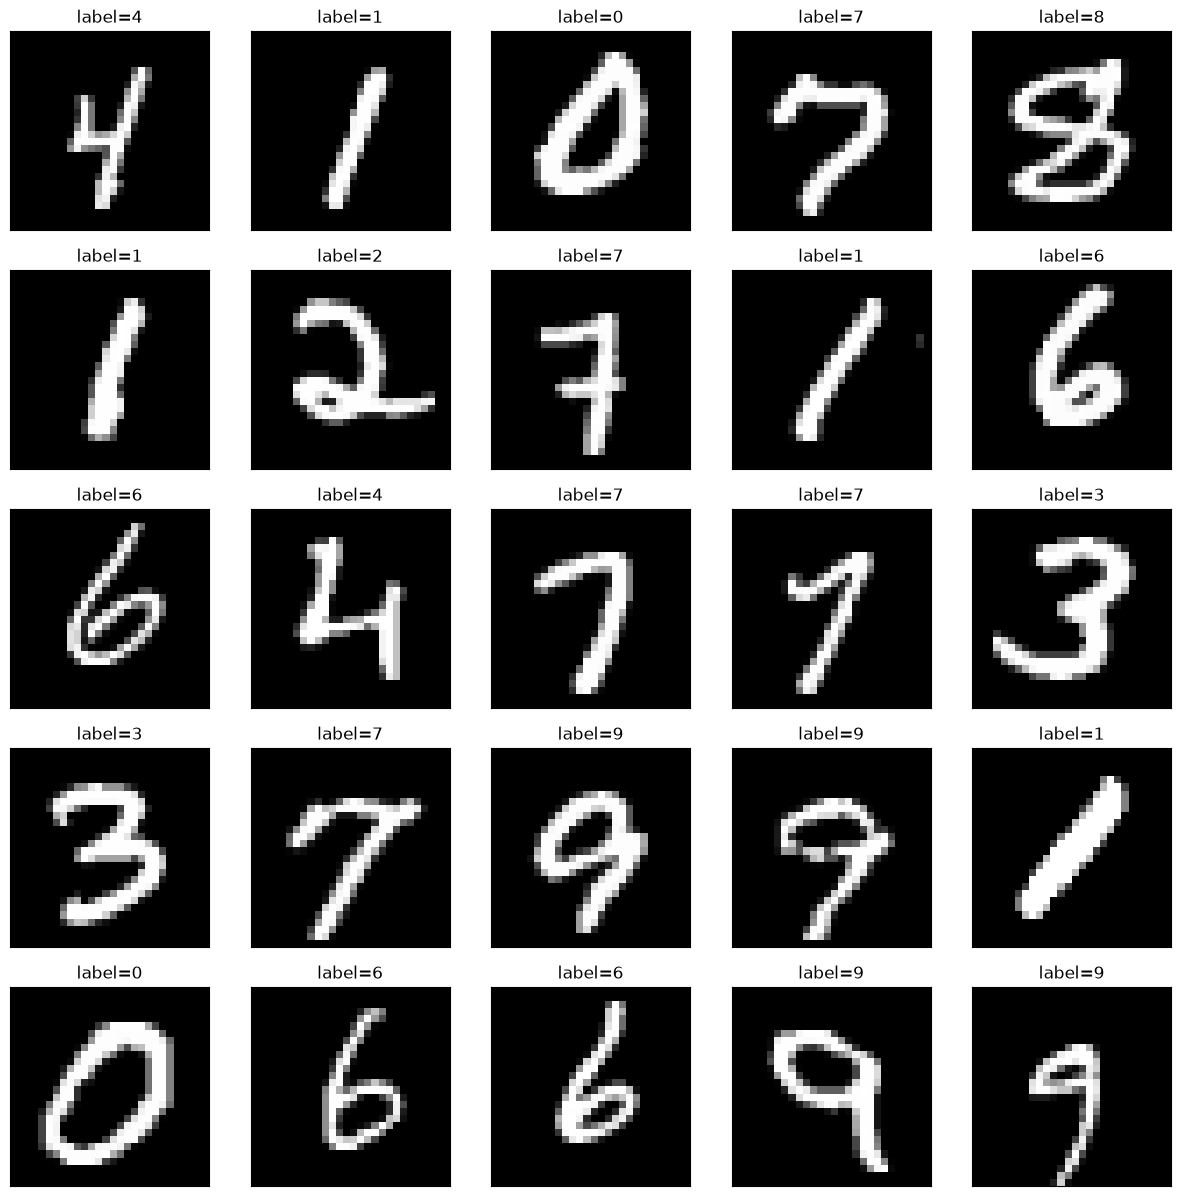

In [6]:
show_img_grid(
    [train_ds['image'][idx] for idx in range(25)],
    [f'label={train_ds["label"][idx]}' for idx in range(25)],
)

## Training

In [7]:
import ml_collections

class CNN(nn.Module):
  """A simple CNN model."""

  @nn.compact
  def __call__(self, x):
    x = nn.Conv(features=32, kernel_size=(3, 3))(x)
    x = nn.relu(x)
    x = nn.avg_pool(x, window_shape=(2, 2), strides=(2, 2))
    x = nn.Conv(features=64, kernel_size=(3, 3))(x)
    x = nn.relu(x)
    x = nn.avg_pool(x, window_shape=(2, 2), strides=(2, 2))
    x = x.reshape((x.shape[0], -1))  # flatten
    x = nn.Dense(features=256)(x)
    x = nn.relu(x)
    x = nn.Dense(features=10)(x)
    return x


@jax.jit
def apply_model(state, images, labels):
  """Computes gradients, loss and accuracy for a single batch."""
  def loss_fn(params):
    logits = state.apply_fn({'params': params}, images)
    one_hot = jax.nn.one_hot(labels, 10)
    loss = jnp.mean(optax.softmax_cross_entropy(logits=logits, labels=one_hot))
    return loss, logits

  grad_fn = jax.value_and_grad(loss_fn, has_aux=True)
  (loss, logits), grads = grad_fn(state.params)
  accuracy = jnp.mean(jnp.argmax(logits, -1) == labels)
  return grads, loss, accuracy


@jax.jit
def update_model(state, grads):
  updates, new_opt_state = state.tx.update(
      grads, state.opt_state, state.params)
  new_params = optax.apply_updates(state.params, updates)
  return state.replace(
      step=state.step + 1,
      params=new_params,
      opt_state=new_opt_state)


def train_epoch(state, train_ds, batch_size, rng, sparsity_updater):
  """Train for a single epoch."""
  train_ds_size = len(train_ds['image'])
  steps_per_epoch = train_ds_size // batch_size

  perms = jax.random.permutation(rng, len(train_ds['image']))
  perms = perms[:steps_per_epoch * batch_size]  # skip incomplete batch
  perms = perms.reshape((steps_per_epoch, batch_size))

  epoch_loss = []
  epoch_accuracy = []
  is_ste = isinstance(sparsity_updater, (jaxpruner.SteMagnitudePruning,
                                         jaxpruner.SteRandomPruning))
  pre_op = jax.jit(sparsity_updater.pre_forward_update)
  post_op = jax.jit(sparsity_updater.post_gradient_update)
  for i, perm in enumerate(perms):
    batch_images = train_ds['image'][perm, ...]
    batch_labels = train_ds['label'][perm, ...]
    # Following is only needed for STE.
    new_params = pre_op(state.params, state.opt_state)
    forward_state = state.replace(params=new_params)

    grads, loss, accuracy = apply_model(forward_state, batch_images,
                                        batch_labels)
    state = update_model(state, grads)
    post_params = post_op(state.params, state.opt_state)
    state = state.replace(params=post_params)
    epoch_loss.append(loss)
    epoch_accuracy.append(accuracy)
    if i % 100 == 0:
      if is_ste:
        print(jaxpruner.summarize_sparsity(
            new_params, only_total_sparsity=True))
      else:
        print(jaxpruner.summarize_sparsity(
            state.params, only_total_sparsity=True))
  train_loss = np.mean(epoch_loss)
  train_accuracy = np.mean(epoch_accuracy)
  return state, train_loss, train_accuracy


def create_train_state(rng, config):
  """Creates initial `TrainState`."""
  cnn = CNN()
  params = cnn.init(rng, jnp.ones([1, 28, 28, 1]))['params']
  sparsity_updater = jaxpruner.create_updater_from_config(config.sparsity_config)
  tx = optax.sgd(config.learning_rate, config.momentum)
  tx = sparsity_updater.wrap_optax(tx)

  return train_state.TrainState.create(
      apply_fn=cnn.apply, params=params, tx=tx), sparsity_updater


import time

def train_and_evaluate(config: ml_collections.ConfigDict
                       ) -> train_state.TrainState:
  """Execute model training and evaluation loop.

  Args:
    config: Hyperparameter configuration for training and evaluation.
    workdir: Directory where the tensorboard summaries are written to.

  Returns:
    The train state (which includes the `.params`).
  """
  train_ds, test_ds = get_datasets()
  rng = jax.random.PRNGKey(0)

  rng, init_rng = jax.random.split(rng)

  state, sparsity_updater = create_train_state(init_rng, config)

  for epoch in range(1, config.num_epochs + 1):
    s_time = time.time()
    rng, input_rng = jax.random.split(rng)
    state, train_loss, train_accuracy = train_epoch(state, train_ds,
                                                    config.batch_size,
                                                    input_rng,
                                                    sparsity_updater)
    # Following is only needed for STE.
    new_params = sparsity_updater.pre_forward_update(
        state.params, state.opt_state)
    forward_state = state.replace(params=new_params)

    _, test_loss, test_accuracy = apply_model(forward_state, test_ds['image'],
                                              test_ds['label'])

    print(
        'epoch:% 3d, train_loss: %.4f, train_accuracy: %.2f, test_loss: %.4f, test_accuracy: %.2f, time: %.2f'
        % (epoch, train_loss, train_accuracy * 100, test_loss,
           test_accuracy * 100, time.time() - s_time))

  return forward_state

# Jaxpruner API

In [8]:
jaxpruner.all_algorithm_names()

('no_prune',
 'magnitude',
 'random',
 'saliency',
 'magnitude_ste',
 'random_ste',
 'global_magnitude',
 'global_saliency',
 'static_sparse',
 'rigl',
 'set')

In [9]:
config = ml_collections.ConfigDict()

config.learning_rate = 0.1
config.momentum = 0.9
config.batch_size = 128
config.num_epochs = 3 # 1 epoch is 468 steps for bs=128

config.sparsity_config = ml_collections.ConfigDict()
config.sparsity_config.algorithm = 'magnitude'
config.sparsity_config.update_freq = 10
config.sparsity_config.update_end_step = 1000
config.sparsity_config.update_start_step = 200
config.sparsity_config.sparsity = 0.95
config.sparsity_config.dist_type = 'erk'

In [10]:
jaxpruner.create_updater_from_config(config.sparsity_config)

MagnitudePruning(scheduler=PolynomialSchedule(update_freq=10, update_start_step=200, update_end_step=1000, power=3), skip_gradients=False, is_sparse_gradients=False, sparsity_type=Unstructured(), sparsity_distribution_fn=functools.partial(<function erk at 0x7f9f27fe6200>, sparsity=0.95), rng_seed=Array([0, 8], dtype=uint32), use_packed_masks=False, topk_fn=<function topk_mask_calculator at 0x7f9f27fe5c60>)

In [11]:
# 3 epochs trains in 10 seconds in the GPU Colab...

state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

{'_total_sparsity': Array(0.8773279, dtype=float32), '_nparams_nnz': Array(101138., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.92426175, dtype=float32), '_nparams_nnz': Array(62443., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.9446, dtype=float32), '_nparams_nnz': Array(45675., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  2, train_loss: 0.0538, train_accuracy: 98.33, test_loss: 0.0391, test_accuracy: 98.72, time: 0.64


{'_total_sparsity': Array(0.9489725, dtype=float32), '_nparams_nnz': Array(42070., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  3, train_loss: 0.0367, train_accuracy: 98.84, test_loss: 0.0295, test_accuracy: 99.04, time: 0.71


# One Shot pruning

In [12]:
config.sparsity_config.update_start_step = 0
config.sparsity_config.update_end_step = 0
config.sparsity_config.skip_gradients=True
state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  2, train_loss: 0.1216, train_accuracy: 96.27, test_loss: 0.0878, test_accuracy: 97.32, time: 0.59
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0875, train_accuracy: 97.28, test_loss: 0.0847, test_accuracy: 97.21, time: 0.60


# STE

In [13]:
# STE also supports gradual pruning schedules.
# Here we train weights with sparse forward pass from the start.
config.sparsity_config.algorithm = 'magnitude_ste'
config.sparsity_config.sparsity = 0.95
config.sparsity_config.update_end_step = 0
config.sparsity_config.update_start_step = 0
config.sparsity_config.dist_type = 'erk'
state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

epoch:  2, train_loss: 0.0821, train_accuracy: 97.45, test_loss: 0.0547, test_accuracy: 98.34, time: 1.73


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0544, train_accuracy: 98.30, test_loss: 0.0410, test_accuracy: 98.69, time: 1.64


# Global Pruning

In [14]:
config.sparsity_config.algorithm = 'global_magnitude'
config.sparsity_config.update_freq = 10
config.sparsity_config.update_end_step = 1000
config.sparsity_config.update_start_step = 200
config.sparsity_config.sparsity = 0.95
config.sparsity_config.dist_type = 'erk'

state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

{'_total_sparsity': Array(0.8773291, dtype=float32), '_nparams_nnz': Array(101137., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.924263, dtype=float32), '_nparams_nnz': Array(62442., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.9446024, dtype=float32), '_nparams_nnz': Array(45673., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  2, train_loss: 0.0514, train_accuracy: 98.41, test_loss: 0.0364, test_accuracy: 98.88, time: 0.60
{'_total_sparsity': Array(0.9489738, dtype=float32), '_nparams_nnz': Array(42069., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958264, dtype=float32), '_nparams_nnz': Array(41567., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958264, dtype=float32), '_nparams_nnz': Array(41567., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958264, dtype=float32), '_nparams_nnz': Array(41567., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958264, dtype=float32), '_nparams_nnz': Array(41567., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0368, train_accuracy: 98.86, test_loss: 0.0287, test_accuracy: 99.07, time: 0.70


In [15]:
jaxpruner.summarize_sparsity(state.opt_state.masks)

{'Conv_0/bias': None,
 'Conv_0/kernel': Array(0.0486111, dtype=float32),
 'Conv_1/bias': None,
 'Conv_1/kernel': Array(0.39371747, dtype=float32),
 'Dense_0/bias': None,
 'Dense_0/kernel': Array(0.9652399, dtype=float32),
 'Dense_1/bias': None,
 'Dense_1/kernel': Array(0.27734375, dtype=float32),
 '_total_sparsity': Array(0.94999975, dtype=float32),
 '_nparams_nnz': Array(41205., dtype=float32),
 '_nparams': Array(824096., dtype=float32)}

# Dynamic Sparse Training

In [16]:
config.sparsity_config.algorithm = 'rigl'

config.sparsity_config.update_freq = 10
config.sparsity_config.update_end_step = 1000
config.sparsity_config.update_start_step = 1
config.sparsity_config.sparsity = 0.95
config.sparsity_config.dist_type = 'erk'

state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.9495838, dtype=float32), '_nparams_nnz': Array(41566., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  2, train_loss: 0.1142, train_accuracy: 96.52, test_loss: 0.0842, test_accuracy: 97.26, time: 0.61
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0779, train_accuracy: 97.58, test_loss: 0.0628, test_accuracy: 97.95, time: 0.57


In [17]:
config.sparsity_config.algorithm = 'set'
state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

{'_total_sparsity': Array(0.94987375, dtype=float32), '_nparams_nnz': Array(41327., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.9497209, dtype=float32), '_nparams_nnz': Array(41453., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94964206, dtype=float32), '_nparams_nnz': Array(41518., dtype=float32), '_nparams': Array(824458., dtype=float32)}
epoch:  2, train_loss: 0.1319, train_accuracy: 96.00, test_loss: 0.1005, test_accuracy: 97.00, time: 0.65
{'_total_sparsity': Array(0.9496057, dtype=float32), '_nparams_nnz': Array(41548., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0856, train_accuracy: 97.40, test_loss: 0.0696, test_accuracy: 97.65, time: 0.61


In [18]:
config.sparsity_config.algorithm = 'static_sparse'

state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

epoch:  1, train_loss: 0.4880, train_accuracy: 84.90, test_loss: 0.1649, test_accuracy: 95.07, time: 1.00
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  2, train_loss: 0.1495, train_accuracy: 95.47, test_loss: 0.1067, test_accuracy: 96.54, time: 0.53
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0.94958144, dtype=float32), '_nparams_nnz': Array(41568., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.1043, train_accuracy: 96.86, test_loss: 0.0968, test_accuracy: 96.89, time: 0.45


# Pruning After Training

In [19]:
config.sparsity_config.algorithm = 'no_prune'
state = train_and_evaluate(config)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


...

epoch:  1, train_loss: 0.2311, train_accuracy: 93.35, test_loss: 0.0563, test_accuracy: 97.96, time: 0.86
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  2, train_loss: 0.0495, train_accuracy: 98.44, test_loss: 0.0343, test_accuracy: 98.77, time: 0.48
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}


{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}
{'_total_sparsity': Array(0., dtype=float32), '_nparams_nnz': Array(824458., dtype=float32), '_nparams': Array(824458., dtype=float32)}


epoch:  3, train_loss: 0.0341, train_accuracy: 98.89, test_loss: 0.0298, test_accuracy: 98.86, time: 0.49


In [20]:
config.sparsity_config.algorithm = 'magnitude'
config.sparsity_config.sparsity = 0.9
sparsity_updater = jaxpruner.create_updater_from_config(config.sparsity_config)
pruned_params, _ = sparsity_updater.instant_sparsify(state.params)
print(jaxpruner.summarize_sparsity(pruned_params, only_total_sparsity=True))

{'_total_sparsity': Array(0.8996031, dtype=float32), '_nparams_nnz': Array(82773., dtype=float32), '_nparams': Array(824458., dtype=float32)}


In [21]:
_, test_ds = get_datasets()
pruned_state = state.replace(params=pruned_params)
_, _, test_accuracy  = apply_model(pruned_state, test_ds['image'], test_ds['label'])
print(test_accuracy*100)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split test, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


98.78999


# N:M sparsity

In [22]:
config.sparsity_config.algorithm = 'magnitude'
config.sparsity_config.sparsity_type = 'nm_1,2'
sparsity_updater = jaxpruner.create_updater_from_config(config.sparsity_config)
pruned_params, masks = sparsity_updater.instant_sparsify(state.params)
print(jaxpruner.summarize_sparsity(pruned_params, only_total_sparsity=True))

{'_total_sparsity': Array(0.49805325, dtype=float32), '_nparams_nnz': Array(413834., dtype=float32), '_nparams': Array(824458., dtype=float32)}


In [23]:
masks['Dense_0']['kernel'][0][:16]

Array([1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1], dtype=uint8)

In [24]:
_, test_ds = get_datasets()
pruned_state = state.replace(params=pruned_params)
_, _, test_accuracy  = apply_model(pruned_state, test_ds['image'], test_ds['label'])
print(test_accuracy*100)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split test, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


98.799995


# Block Sparsity

In [25]:
config.sparsity_config.algorithm = 'magnitude'
config.sparsity_config.sparsity = 0.7
config.sparsity_config.sparsity_type = 'block_2,2'
sparsity_updater = jaxpruner.create_updater_from_config(config.sparsity_config)
pruned_params, masks = sparsity_updater.instant_sparsify(state.params)
print(jaxpruner.summarize_sparsity(pruned_params, only_total_sparsity=True))

{'_total_sparsity': Array(0.700892, dtype=float32), '_nparams_nnz': Array(246602., dtype=float32), '_nparams': Array(824458., dtype=float32)}


In [26]:
masks['Dense_0']['kernel'][:4, :16]

Array([[0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=uint8)

In [27]:
_, test_ds = get_datasets()
pruned_state = state.replace(params=pruned_params)
_, _, test_accuracy  = apply_model(pruned_state, test_ds['image'], test_ds['label'])
print(test_accuracy*100)

INFO:absl:Load dataset info from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Reusing dataset mnist (/tmp/jaxpruner-smoke/tfds/mnist/3.0.1)


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split train, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


INFO:absl:Creating a tf.data.Dataset reading 1 files located in folders: /tmp/jaxpruner-smoke/tfds/mnist/3.0.1.


INFO:absl:Constructing tf.data.Dataset mnist for split test, from /tmp/jaxpruner-smoke/tfds/mnist/3.0.1


43.329998
